# Federated learning on SIPaKMeD: FedAvg vs Optimized Clustered FedAvg (+ top-k / delta compression)

**What this notebook does**

1. Compares **FedAvg** with **Clustered FedAvg+** (an improved clustered method) on **IID** and **non-IID** data, with **3, 5 and 10 clients**.
2. Tests **communication reduction**: clients send only the **weight change (delta)**, and only its **top-k** largest entries, with error feedback.
3. Saves every run to `results/*.csv` (so you can stop and resume) and draws the comparison graphs.

**How to use it**

- Put this file in the same folder as `federated_sipakmed.py` (your `Final-Proj` folder). It imports your script's data loader, model builder, local training and evaluation functions.
- Select the kernel that has `torch`, `torchvision` and `ultralytics` (your `.venv311`).
- Run the cells top to bottom. Leave `QUICK = True` for the first run (a few minutes) to check everything works, then set `QUICK = False`.

**Clustered FedAvg+ in one paragraph.** Rounds 1 to `WARMUP_ROUNDS` are plain FedAvg. Then clients are grouped by the *direction of their weight updates* (cosine similarity, after removing the common direction). Each group keeps its own model, but after every round the group model is blended with the global average: `cluster = (1 - BETA) * cluster_avg + BETA * global_avg`, so groups specialise without being starved of data.

**Two ways of measuring accuracy** (both are saved):

- `acc_global`: accuracy on the shared 656-image validation set (for Clustered FedAvg+ this is the ensemble of cluster models, as in your first experiments).
- `acc_personal`: each client is tested on its *own* validation images (same label mix as its training data) using the model it actually trains from. This is the fair test for personalization.

In [1]:
import sys, time, copy, gc, json, re
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader, Subset
from torchvision import transforms
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd()))
import federated_sipakmed as fs   # your existing script (must be in this folder)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", device, "| cwd:", Path.cwd())

torch 2.5.1+cpu | device: cpu | cwd: c:\Users\abhav\Final-Proj


## 1. Configuration

Everything you may want to change is in this one cell.

In [2]:
# ---- data / model (same values as your earlier runs) ----
DATA_DIR      = Path("data/sipakmed_binary")
WEIGHTS       = "yolov8n-cls.pt"
IMAGE_SIZE    = 96
BATCH_SIZE    = 8
LOCAL_EPOCHS  = 2
LR            = 1e-3
WEIGHT_DECAY  = 1e-4
VAL_FRACTION  = 0.2
PROX_MU       = 0.0     # >0 adds a FedProx penalty to BOTH methods; 0 keeps the comparison clean

# ---- experiment grid ----
ROUNDS        = 20
SEEDS         = [42]                       # use [42, 43, 44] later for mean +/- std
CLIENT_COUNTS = [3, 5, 10]
SCENARIOS     = {
    "IID": None,
    "Mild non-IID (alpha=1.0)": 1.0,
    "Moderate non-IID (alpha=0.5)": 0.5,
    "Extreme non-IID (alpha=0.1)": 0.1,
    "non-IID (alpha=0.5)": 0.5
}
CLUSTERS_FOR  = {3: 2, 5: 3, 10: 3}        # number of clusters for each client count

# ---- Clustered FedAvg+ ----
WARMUP_ROUNDS = 3       # plain FedAvg rounds before clustering
BETA          = 0.3     # 0 = pure clusters, 1 = pure FedAvg

# ---- compression experiment ----
COMPRESSION_RATIOS  = [0.1, 0.01]   # fraction of each tensor's update that is sent (top-k)
COMPRESSION_CLIENTS = [5]

# ---- partition safety limits ----
MIN_TRAIN_PER_CLIENT = 30
MIN_VAL_PER_CLIENT   = 5

# ---- quick smoke test: set to False for the real experiment ----
QUICK = True
RESULTS_DIR = Path("results")
if QUICK:
    ROUNDS, WARMUP_ROUNDS = 4, 2
    CLIENT_COUNTS, COMPRESSION_CLIENTS = [3], [3]
    COMPRESSION_RATIOS = [0.1]
    RESULTS_DIR = Path("results_quick")
RESULTS_DIR.mkdir(exist_ok=True)

METHOD_NAMES = {
    "fedavg": "FedAvg",
    "clustered_plus": "Clustered FedAvg+",
    "normal_clustered": "Normal Clustered FedAvg",
    "optimized_clustered": "Optimized Clustered FedAvg (IFCA+Blend)",
    "cka_clustered": "CKA Clustered FedAvg",
}
MiB = 1024 ** 2
print("QUICK mode:" , QUICK, "| results ->", RESULTS_DIR)

QUICK mode: True | results -> results_quick


## 2. Load the images once and keep them in memory

The images are resized once and stored as one tensor (about 450 MB at 96x96). This makes every round much faster than re-reading files from disk. The preprocessing is identical to your script.

In [3]:
transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
])
raw = fs.BinaryImageFolder(DATA_DIR, transform=transform, class_to_binary=fs.CLASS_TO_BINARY)
print("Image source:", raw.image_source, "| images:", len(raw))

t0 = time.time()
ALL_X = torch.empty(len(raw), 3, IMAGE_SIZE, IMAGE_SIZE)
ALL_Y = torch.empty(len(raw), dtype=torch.long)
for i in range(len(raw)):
    x, y = raw[i]
    ALL_X[i], ALL_Y[i] = x, y
FULL = TensorDataset(ALL_X, ALL_Y)
LABELS = ALL_Y.tolist()
del raw
print(f"Cached {len(FULL)} images in {time.time() - t0:.0f}s | abnormal (1): {sum(LABELS)} | normal (0): {len(LABELS) - sum(LABELS)}")

Image source: CROPPED cell images | images: 4049
Cached 4049 images in 10s | abnormal (1): 1638 | normal (0): 2411


## 3. IID and non-IID partitioning

- **IID**: every client gets the same share of each class, chosen at random.
- **non-IID (Dirichlet)**: for each class, the share given to each client is drawn from a Dirichlet(alpha) distribution. Small alpha means very uneven clients (some mostly abnormal, some mostly normal).
- The **validation images are split with the same shares**, so every client also has a validation set that looks like its training data. That is what the personalized accuracy uses.

In [4]:
def make_split(seed):
    """Balanced 80/20 stratified train/validation split (global image indices)."""
    balanced = fs.balanced_binary_indices(LABELS, seed)
    bal_labels = [LABELS[i] for i in balanced]
    tr, va = fs.stratified_train_validation_split(bal_labels, VAL_FRACTION, seed)
    return [balanced[i] for i in tr], [balanced[i] for i in va]


def split_by_props(indices, props, rng):
    parts = [[] for _ in range(len(props[0]))]
    for label in (0, 1):
        idx = [i for i in indices if LABELS[i] == label]
        rng.shuffle(idx)
        cuts = (np.cumsum(props[label]) * len(idx)).astype(int)[:-1]
        for part, chunk in zip(parts, np.split(np.array(idx, dtype=int), cuts)):
            part.extend(chunk.tolist())
    return parts


def partition_clients(train_idx, val_idx, n_clients, alpha, seed):
    rng = np.random.default_rng([seed, n_clients])
    for _ in range(1000):
        if alpha is None:
            props = {lab: np.full(n_clients, 1.0 / n_clients) for lab in (0, 1)}
        else:
            props = {lab: rng.dirichlet([alpha] * n_clients) for lab in (0, 1)}
        train_parts = split_by_props(train_idx, props, rng)
        val_parts = split_by_props(val_idx, props, rng)
        if (min(map(len, train_parts)) >= MIN_TRAIN_PER_CLIENT
                and min(map(len, val_parts)) >= MIN_VAL_PER_CLIENT):
            return train_parts, val_parts
    raise RuntimeError("Could not build a valid partition; use a larger alpha or fewer clients.")

## 4. Sending only weight changes + top-k (with error feedback)

- **Delta**: the client sends `delta = w_new - w_start` instead of the full model. On its own this is lossless and does *not* make the message smaller (same number of values). It is what makes the next step possible.
- **Top-k**: in every weight tensor, only the `ratio` fraction of entries with the largest `|delta|` are sent, as (value, index) pairs. That costs 4 + 4 bytes per kept entry.
- **Error feedback**: the part that was *not* sent is stored on the client and added to its next update, so nothing is permanently lost.
- The server rebuilds `w_start + sparse_delta` and averages as usual.
- The **download** (server to client) stays a full model, so total traffic falls less than upload traffic. Both are recorded.

In [5]:
def topk_sparsify(delta, residual, ratio):
    """Per-tensor top-k with error feedback. Returns (sent_delta, new_residual, upload_bytes)."""
    sent, new_residual, upload_bytes = {}, {}, 0
    for name, d in delta.items():
        v = d + residual[name]
        flat = v.reshape(-1)
        k = max(1, int(ratio * flat.numel()))
        idx = flat.abs().topk(k).indices
        kept = torch.zeros_like(flat)
        kept[idx] = flat[idx]
        kept = kept.view_as(v)
        sent[name] = kept
        new_residual[name] = v - kept
        # 4-byte value + 4-byte index per kept entry (never more than sending the tensor densely)
        upload_bytes += min(k * (v.element_size() + 4), v.numel() * v.element_size())
    return sent, new_residual, upload_bytes


def rebuild_state(start, sent, updated):
    """Server side: start + received delta for float tensors; integer counters are taken as sent."""
    return {k: (start[k] + sent[k]) if k in sent else updated[k].clone() for k in start}

## 5. Clustered FedAvg+ helpers

- `cluster_clients_by_updates`: clients are grouped by the **direction of their weight updates** (cosine similarity, after subtracting the mean update so the shared direction does not hide the differences). Farthest-first initialisation makes it deterministic.
- `blend`: `cluster_model = (1 - beta) * cluster_avg + beta * global_avg`.

In [6]:
def flat_update(delta):
    """One vector per client (batch-norm running statistics are excluded)."""
    return torch.cat([v.reshape(-1) for k, v in delta.items() if "running_" not in k])


def cluster_clients_by_updates(updates, n_clusters):
    X = torch.stack([updates[c] for c in sorted(updates)])
    X = F.normalize(X - X.mean(dim=0, keepdim=True), dim=1)
    centers = [X[0]]
    while len(centers) < n_clusters:                      # farthest-first initialisation
        best = torch.stack([X @ c for c in centers]).max(dim=0).values
        centers.append(X[best.argmin()])
    C = torch.stack(centers)
    for _ in range(50):                                   # spherical k-means
        assign = (X @ C.T).argmax(dim=1)
        new_C = C.clone()
        for j in range(n_clusters):
            members = X[assign == j]
            if len(members):
                new_C[j] = F.normalize(members.mean(dim=0), dim=0)
        if torch.allclose(new_C, C):
            break
        C = new_C
    groups = [[c for c, a in enumerate(assign.tolist()) if a == j] for j in range(n_clusters)]
    return [g for g in groups if g]


def blend(cluster_state, global_state, beta):
    out = {}
    for k, v in cluster_state.items():
        if torch.is_floating_point(v):
            out[k] = ((1.0 - beta) * v + beta * global_state[k]).to(v.dtype)
        else:
            out[k] = v.clone()
    return out

## 6. One experiment run

`run_experiment` trains one method on one scenario, writes `results/<run>.csv` (one row per round) and skips runs that already have a file, so you can stop and continue later.

In [7]:
def slug(text):
    return re.sub(r"[^A-Za-z0-9]+", "_", text).strip("_")


def run_experiment(method, scenario, n_clients, seed, k_ratio=1.0):
    assert method in METHOD_NAMES
    out_path = RESULTS_DIR / f"{method}__{slug(scenario)}__{n_clients}c__k{k_ratio}__s{seed}.csv"
    if out_path.exists():
        print("skip (already done):", out_path.name)
        return pd.read_csv(out_path)

    alpha = SCENARIOS[scenario]
    clustered = method == "clustered_plus"
    n_clusters = CLUSTERS_FOR[n_clients]

    fs.set_seed(seed)
    train_idx, val_idx = make_split(seed)
    train_parts, val_parts = partition_clients(train_idx, val_idx, n_clients, alpha, seed)
    sizes = [len(p) for p in train_parts]
    abnormal_share = [round(sum(LABELS[i] for i in p) / len(p), 2) for p in train_parts]
    print(f"\n=== {METHOD_NAMES[method]} | {scenario} | {n_clients} clients | top-k={k_ratio} | seed {seed}")
    print(f"client sizes {sizes} | abnormal share per client {abnormal_share}")

    val_loader = DataLoader(Subset(FULL, val_idx), batch_size=32, shuffle=False)
    client_val_loaders = [DataLoader(Subset(FULL, p), batch_size=32, shuffle=False) for p in val_parts]

    template = fs.build_model(WEIGHTS, IMAGE_SIZE)
    global_state = fs.cpu_state_dict(template)
    float_keys = [k for k, v in global_state.items() if torch.is_floating_point(v)]
    model_bytes = fs.state_dict_nbytes(global_state)
    float_bytes = sum(global_state[k].numel() * global_state[k].element_size() for k in float_keys)
    nonfloat_bytes = model_bytes - float_bytes
    eval_model = copy.deepcopy(template).to(device)

    compress = k_ratio < 1.0
    residuals = ({c: {k: torch.zeros_like(global_state[k]) for k in float_keys} for c in range(n_clients)}
                 if compress else None)
    cluster_states, groups = None, []
    client_cluster = {c: 0 for c in range(n_clients)}
    warm_updates = {}
    cum_up = cum_down = 0

    history = []
    for rnd in range(1, ROUNDS + 1):
        t0 = time.time()
        use_clusters = clustered and cluster_states is not None
        cluster_acc = [fs.WeightedStateAccumulator() for _ in range(len(cluster_states) if use_clusters else 1)]
        global_acc = fs.WeightedStateAccumulator()
        round_up = 0

        for cid in range(n_clients):
            start = cluster_states[client_cluster[cid]] if use_clusters else global_state
            updated = fs.local_train(
                model_template=template, initial_state=start, dataset=FULL, indices=train_parts[cid],
                device=device, batch_size=BATCH_SIZE, workers=0, epochs=LOCAL_EPOCHS,
                learning_rate=LR, weight_decay=WEIGHT_DECAY,
                regularizer="fedprox" if PROX_MU > 0 else None, regularizer_coefficient=PROX_MU,
                seed=seed + rnd * 1009 + cid,
            )
            delta = {k: updated[k] - start[k] for k in float_keys}      # send the CHANGE, not the model
            if compress:
                sent, residuals[cid], float_up = topk_sparsify(delta, residuals[cid], k_ratio)
                round_up += float_up + nonfloat_bytes
            else:
                sent = delta
                round_up += model_bytes
            state_hat = rebuild_state(start, sent, updated)             # what the server reconstructs
            cluster_acc[client_cluster[cid] if use_clusters else 0].add(state_hat, sizes[cid])
            global_acc.add(state_hat, sizes[cid])
            if clustered and not use_clusters:
                warm_updates[cid] = flat_update(sent)
            del updated, delta, sent, state_hat

        global_state = global_acc.finish(global_state)
        if use_clusters:
            averaged = [a.finish(s) for a, s in zip(cluster_acc, cluster_states)]
            cluster_states = [blend(c, global_state, BETA) for c in averaged]
        elif clustered and rnd == WARMUP_ROUNDS:
            groups = cluster_clients_by_updates(warm_updates, n_clusters)
            client_cluster = {c: j for j, g in enumerate(groups) for c in g}
            cluster_states = [copy.deepcopy(global_state) for _ in groups]
            shares = [[abnormal_share[c] for c in g] for g in groups]
            print(f"  clustering after round {rnd}: groups {groups} | abnormal share inside groups {shares}")

        cum_up += round_up
        cum_down += n_clients * model_bytes

        # ---- evaluation ----
        if clustered and cluster_states is not None:
            eval_states = cluster_states                                  # ensemble of cluster models
            own_state = lambda c: cluster_states[client_cluster[c]]
        else:
            eval_states = [global_state]
            own_state = lambda c: global_state
        m = fs.evaluate(eval_model, eval_states, val_loader, device)
        correct = total = 0.0
        for cid in range(n_clients):
            n_val = len(val_parts[cid])
            acc = fs.evaluate(eval_model, [own_state(cid)], client_val_loaders[cid], device)["top1_accuracy"]
            correct += acc * n_val
            total += n_val
        acc_personal = correct / total

        history.append(dict(
            method=method, scenario=scenario, n_clients=n_clients, k_ratio=k_ratio, seed=seed, round=rnd,
            acc_global=m["top1_accuracy"], f1_global=m["macro_f1"], recall=m["recall"],
            specificity=m["specificity"], acc_personal=acc_personal,
            upload_MiB=round_up / MiB, download_MiB=n_clients * model_bytes / MiB,
            cum_upload_MiB=cum_up / MiB, cum_total_MiB=(cum_up + cum_down) / MiB,
            clusters=json.dumps(groups) if groups else "", seconds=time.time() - t0,
        ))
        print(f"  round {rnd:02d}/{ROUNDS} | global acc {m['top1_accuracy']:.4f} | personal acc {acc_personal:.4f} "
              f"| upload {round_up / MiB:.2f} MiB | {time.time() - t0:.0f}s")

    df = pd.DataFrame(history)
    df.to_csv(out_path, index=False)
    del eval_model, template, residuals
    gc.collect()
    return df


def run_grid(methods, scenarios, counts, seeds, k_ratios):
    for seed in seeds:
        for scenario in scenarios:
            for n in counts:
                for k in k_ratios:
                    for method in methods:
                        run_experiment(method, scenario, n, seed, k)

## 7. Experiment A: FedAvg vs Clustered FedAvg+ (IID and non-IID, 3 / 5 / 10 clients, no compression)

Time one round in the quick run first, then estimate the total as `rounds x runs x time per round`. Full grid: 2 methods x 2 scenarios x 3 client counts = 12 runs per seed.

In [8]:
run_grid(["fedavg", "clustered_plus"], SCENARIOS, CLIENT_COUNTS, SEEDS, [1.0])

skip (already done): fedavg__IID__3c__k1.0__s42.csv
skip (already done): clustered_plus__IID__3c__k1.0__s42.csv
skip (already done): fedavg__Mild_non_IID_alpha_1_0__3c__k1.0__s42.csv
skip (already done): clustered_plus__Mild_non_IID_alpha_1_0__3c__k1.0__s42.csv
skip (already done): fedavg__Moderate_non_IID_alpha_0_5__3c__k1.0__s42.csv
skip (already done): clustered_plus__Moderate_non_IID_alpha_0_5__3c__k1.0__s42.csv
skip (already done): fedavg__Extreme_non_IID_alpha_0_1__3c__k1.0__s42.csv
skip (already done): clustered_plus__Extreme_non_IID_alpha_0_1__3c__k1.0__s42.csv
skip (already done): fedavg__non_IID_alpha_0_5__3c__k1.0__s42.csv
skip (already done): clustered_plus__non_IID_alpha_0_5__3c__k1.0__s42.csv


## 8. Experiment B: communication reduction (delta + top-k)

Same two methods, with only the top `ratio` fraction of every tensor's update uploaded. The dense runs (ratio 1.0) are reused from Experiment A when available.

In [9]:
run_grid(["fedavg", "clustered_plus"], SCENARIOS, COMPRESSION_CLIENTS, SEEDS, [1.0] + COMPRESSION_RATIOS)

skip (already done): fedavg__IID__3c__k1.0__s42.csv
skip (already done): clustered_plus__IID__3c__k1.0__s42.csv
skip (already done): fedavg__IID__3c__k0.1__s42.csv
skip (already done): clustered_plus__IID__3c__k0.1__s42.csv
skip (already done): fedavg__Mild_non_IID_alpha_1_0__3c__k1.0__s42.csv
skip (already done): clustered_plus__Mild_non_IID_alpha_1_0__3c__k1.0__s42.csv
skip (already done): fedavg__Mild_non_IID_alpha_1_0__3c__k0.1__s42.csv
skip (already done): clustered_plus__Mild_non_IID_alpha_1_0__3c__k0.1__s42.csv
skip (already done): fedavg__Moderate_non_IID_alpha_0_5__3c__k1.0__s42.csv
skip (already done): clustered_plus__Moderate_non_IID_alpha_0_5__3c__k1.0__s42.csv
skip (already done): fedavg__Moderate_non_IID_alpha_0_5__3c__k0.1__s42.csv
skip (already done): clustered_plus__Moderate_non_IID_alpha_0_5__3c__k0.1__s42.csv
skip (already done): fedavg__Extreme_non_IID_alpha_0_1__3c__k1.0__s42.csv
skip (already done): clustered_plus__Extreme_non_IID_alpha_0_1__3c__k1.0__s42.csv
skip

## 9. Results

Curves show the mean over seeds, with a shaded band of one standard deviation when you use more than one seed.

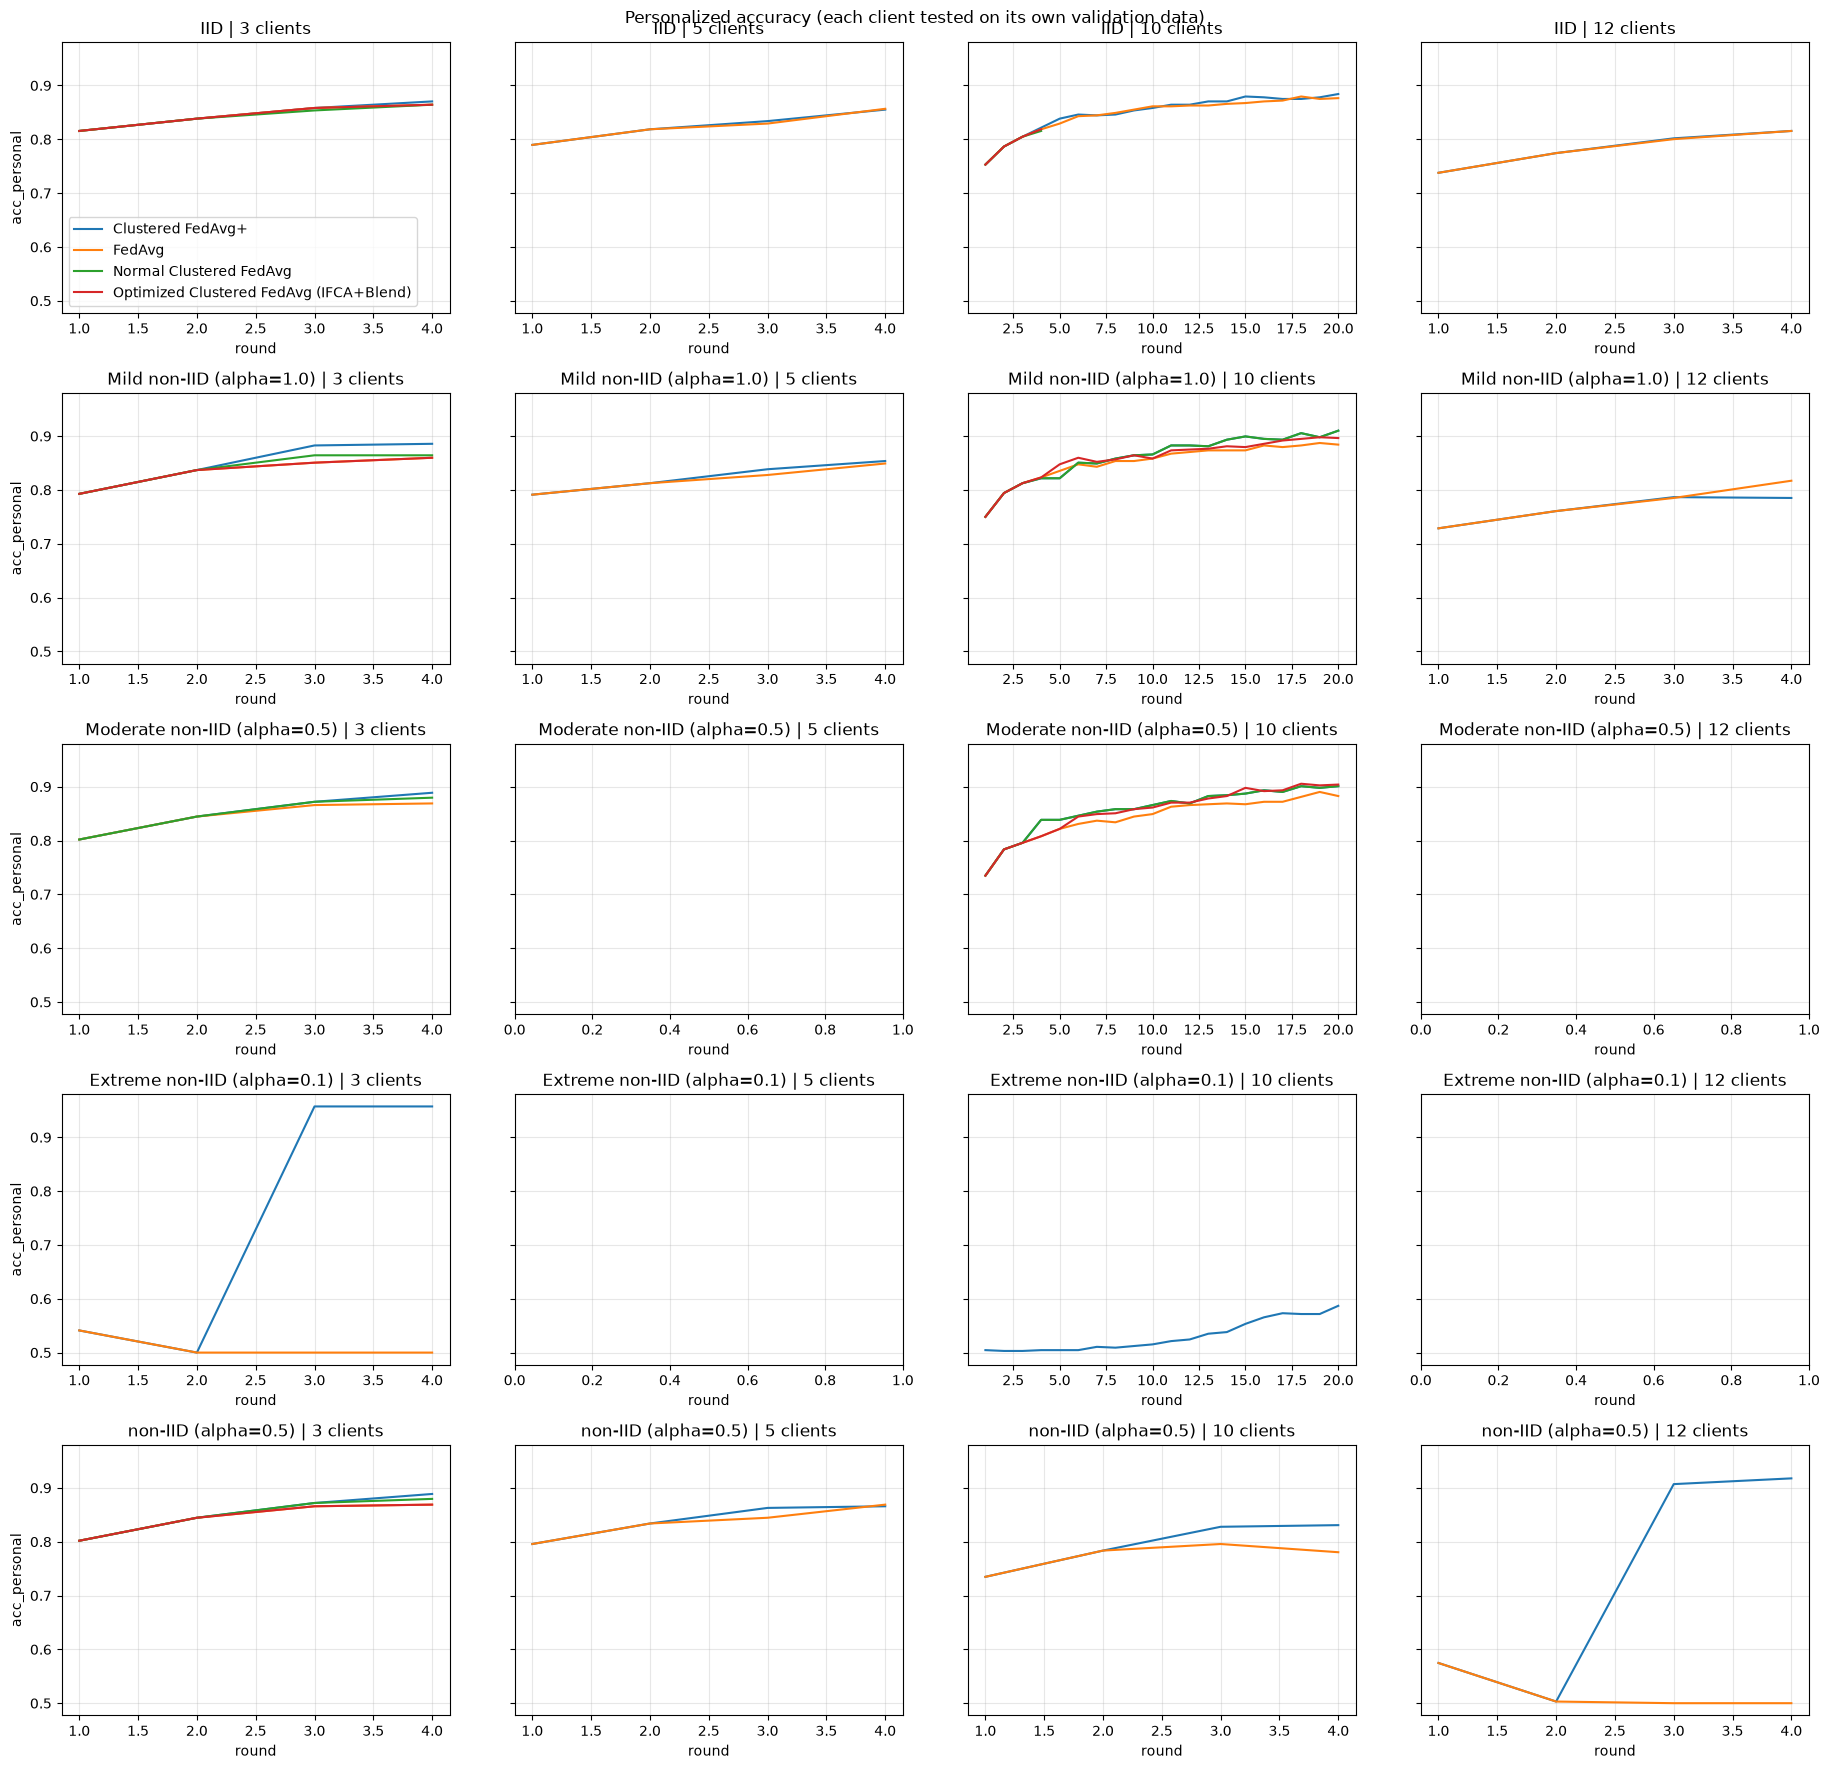

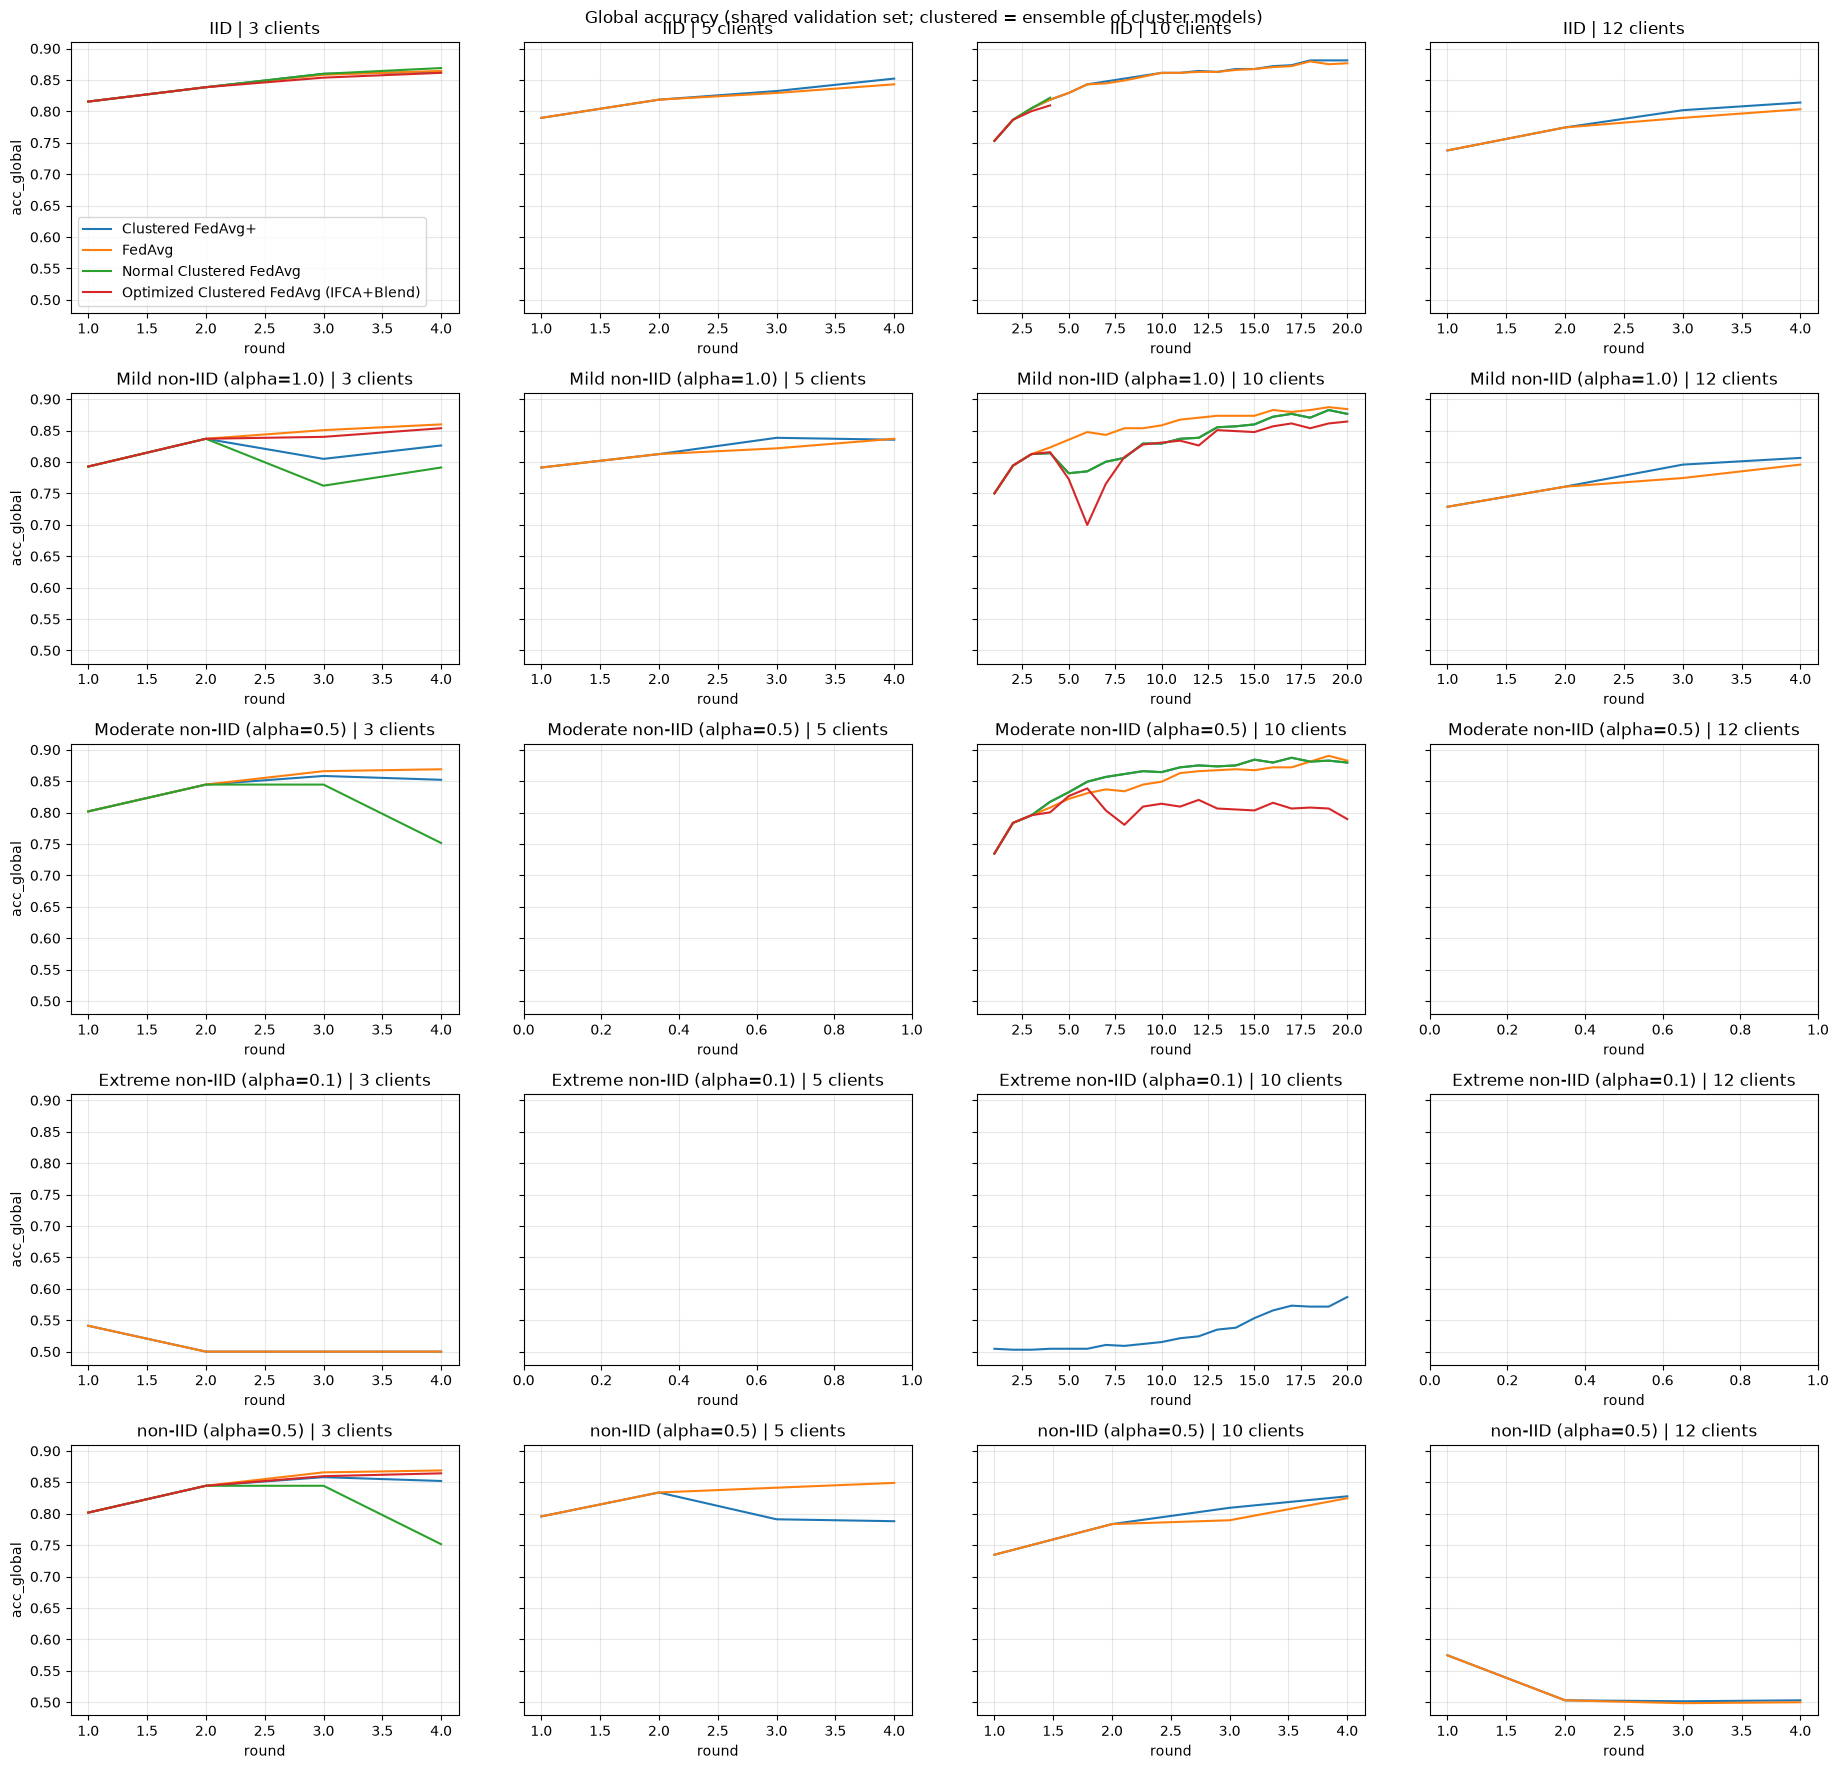

In [10]:
def load_results(results_dir=RESULTS_DIR):
    files = sorted(Path(results_dir).glob("*.csv"))
    if not files:
        raise FileNotFoundError(f"No result files in {results_dir}. Run the experiment cells first.")
    return pd.concat([pd.read_csv(f) for f in files], ignore_index=True)


def plot_curves(df, metric, title):
    dense = df[df.k_ratio == 1.0]
    scenarios = list(dense.scenario.unique())
    counts = sorted(dense.n_clients.unique())
    fig, axes = plt.subplots(len(scenarios), len(counts), figsize=(4.6 * len(counts), 3.6 * len(scenarios)),
                             sharey=True, squeeze=False)
    for i, sc in enumerate(scenarios):
        for j, n in enumerate(counts):
            ax = axes[i][j]
            sub = dense[(dense.scenario == sc) & (dense.n_clients == n)]
            for method, g in sub.groupby("method"):
                stats = g.groupby("round")[metric].agg(["mean", "std"]).fillna(0)
                ax.plot(stats.index, stats["mean"], label=METHOD_NAMES.get(method, method.replace("_", " ").title()))
                ax.fill_between(stats.index, stats["mean"] - stats["std"], stats["mean"] + stats["std"], alpha=0.15)
            ax.set_title(f"{sc} | {n} clients")
            ax.set_xlabel("round")
            ax.grid(alpha=0.3)
            if j == 0:
                ax.set_ylabel(metric)
    axes[0][0].legend()
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


results = load_results()
plot_curves(results, "acc_personal", "Personalized accuracy (each client tested on its own validation data)")
plot_curves(results, "acc_global", "Global accuracy (shared validation set; clustered = ensemble of cluster models)")

In [11]:
def final_table(df):
    last = df.groupby(["method", "scenario", "n_clients", "k_ratio", "seed"]).tail(1)
    table = (last.groupby(["scenario", "n_clients", "k_ratio", "method"])
                 [["acc_personal", "acc_global", "f1_global", "cum_upload_MiB", "cum_total_MiB"]]
                 .agg(["mean", "std"]).round(4))
    return table


print("Final-round results, no compression (mean and std over seeds; std is NaN with one seed)")
final_table(results[results.k_ratio == 1.0])

Final-round results, no compression (mean and std over seeds; std is NaN with one seed)


acc_personal  \
                                                                           mean   
scenario                     n_clients k_ratio method                             
Extreme non-IID (alpha=0.1)  3         1.0     clustered_plus            0.9573   
                                               fedavg                    0.5000   
                             10        1.0     fedavg                    0.5869   
IID                          3         1.0     clustered_plus            0.8704   
                                               fedavg                    0.8643   
                                               normal_clustered          0.8643   
                                               optimized_clustered       0.8643   
                             5         1.0     normal_clustered          0.8552   
                                               optimized_clustered       0.8567   
                             10        1.0     cka_clustered             0.8841   
                                               fedavg                    0.8765   
                                               normal_clustered          0.8155   
                                               optimized_clustered       0.8186   
                             12        1.0     normal_clustered          0.8155   
                                               optimized_clustered       0.8155   
Mild non-IID (alpha=1.0)     3         1.0     clustered_plus            0.8857   
                                               fedavg                    0.8598   
                                               normal_clustered          0.8643   
                                               optimized_clustered       0.8598   
                             5         1.0     normal_clustered          0.8537   
                                               optimized_clustered       0.8491   
                             10        1.0     cka_clustered             0.9101   
                                               fedavg                    0.8841   
                                               normal_clustered          0.9101   
                                               optimized_clustered       0.8963   
                             12        1.0     normal_clustered          0.7851   
                                               optimized_clustered       0.8171   
Moderate non-IID (alpha=0.5) 3         1.0     clustered_plus            0.8887   
                                               fedavg                    0.8689   
                                               normal_clustered          0.8796   
                             10        1.0     cka_clustered             0.9009   
                                               fedavg                    0.8826   
                                               normal_clustered          0.9009   
                                               optimized_clustered       0.9040   
non-IID (alpha=0.5)          3         1.0     clustered_plus            0.8887   
                                               fedavg                    0.8689   
                                               normal_clustered          0.8796   
                                               optimized_clustered       0.8689   
                             5         1.0     normal_clustered          0.8659   
                                               optimized_clustered       0.8689   
                             10        1.0     normal_clustered          0.8308   
                                               optimized_clustered       0.7805   
                             12        1.0     normal_clustered          0.9177   
                                               optimized_clustered       0.5000   

                                                                        \
                                                                   std   
scenario         

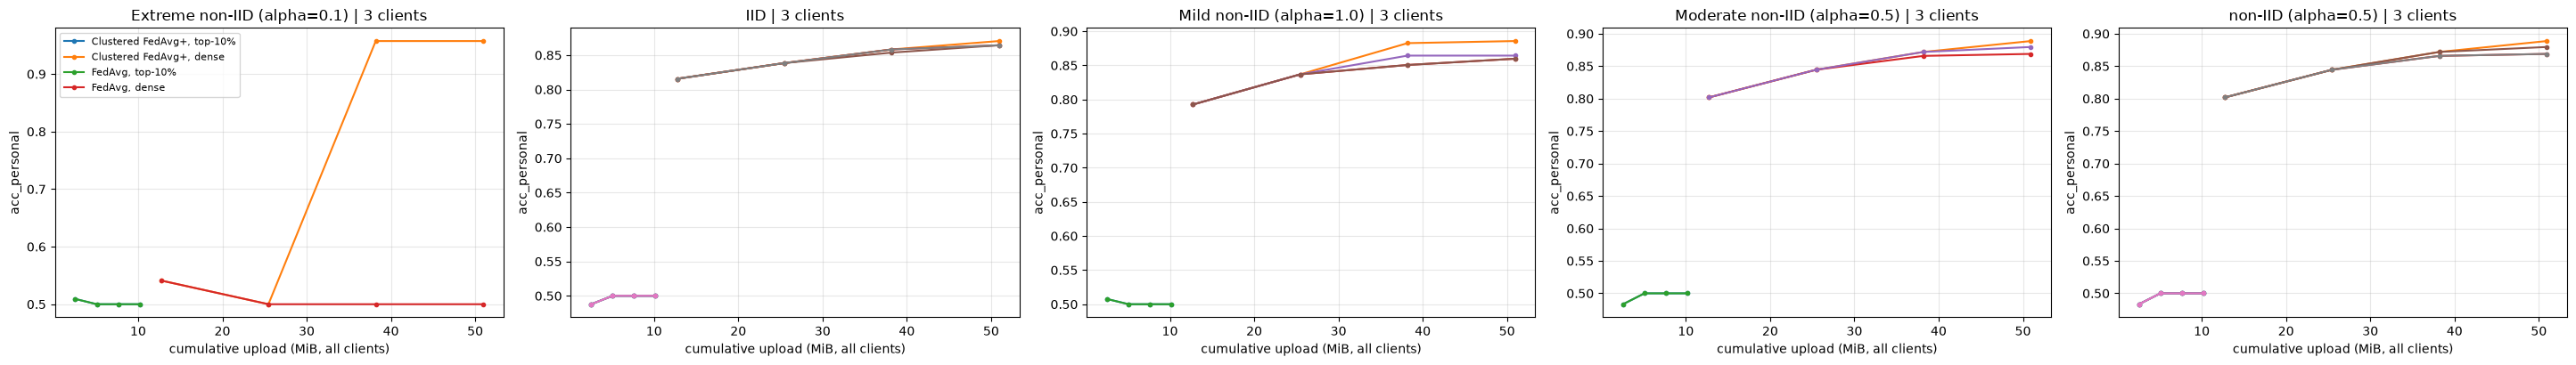

Final-round results with compression


acc_personal  \
                                                                           mean   
scenario                     n_clients k_ratio method                             
Extreme non-IID (alpha=0.1)  3         0.1     clustered_plus            0.5000   
                                               fedavg                    0.5000   
                                       1.0     clustered_plus            0.9573   
                                               fedavg                    0.5000   
IID                          3         0.1     clustered_plus            0.5000   
                                               fedavg                    0.5000   
                                               normal_clustered          0.5000   
                                               optimized_clustered       0.5000   
                                       1.0     clustered_plus            0.8704   
                                               fedavg                    0.8643   
                                               normal_clustered          0.8643   
                                               optimized_clustered       0.8643   
Mild non-IID (alpha=1.0)     3         0.1     clustered_plus            0.5000   
                                               fedavg                    0.5000   
                                       1.0     clustered_plus            0.8857   
                                               fedavg                    0.8598   
                                               normal_clustered          0.8643   
                                               optimized_clustered       0.8598   
Moderate non-IID (alpha=0.5) 3         0.1     clustered_plus            0.5000   
                                               fedavg                    0.5000   
                                       1.0     clustered_plus            0.8887   
                                               fedavg                    0.8689   
                                               normal_clustered          0.8796   
non-IID (alpha=0.5)          3         0.1     clustered_plus            0.5000   
                                               fedavg                    0.5000   
                                               normal_clustered          0.5000   
                                               optimized_clustered       0.5000   
                                       1.0     clustered_plus            0.8887   
                                               fedavg                    0.8689   
                                               normal_clustered          0.8796   
                                               optimized_clustered       0.8689   

                                                                        \
                                                                   std   
scenario                     n_clients k_ratio method                    
Extreme non-IID (alpha=0.1)  3         0.1     clustered_plus      NaN   
                                               fedavg              NaN   
                                       1.0     clustered_plus      NaN   
                                               fedavg              NaN   
IID                          3         0.1     clustered_plus      NaN   
                                               fedavg              NaN   
                                               normal_clustered    NaN   
                                               optimized_clustered NaN   
                                       1.0     clustered_plus      NaN   
                                               fedavg              NaN   
                                               normal_clustered    NaN   
                                               optimized_clustered NaN   
Mild non-IID (alpha=1.0)     3         0.1     clustered_plus      NaN   
                                               fedavg       

In [12]:
def plot_compression(df, n_clients, metric="acc_personal"):
    sub = df[df.n_clients == n_clients]
    scenarios = list(sub.scenario.unique())
    fig, axes = plt.subplots(1, len(scenarios), figsize=(5.8 * len(scenarios), 4.2), squeeze=False)
    for ax, sc in zip(axes[0], scenarios):
        for (method, k), g in sub[sub.scenario == sc].groupby(["method", "k_ratio"]):
            stats = g.groupby("round").agg(x=("cum_upload_MiB", "mean"), y=(metric, "mean"))
            method_name = METHOD_NAMES.get(method, method.replace("_", " ").title())
            label = f"{method_name}, " + ("dense" if k == 1.0 else f"top-{k:.0%}")
            ax.plot(stats.x, stats.y, marker="o", markersize=3, label=label)
        ax.set_title(f"{sc} | {n_clients} clients")
        ax.set_xlabel("cumulative upload (MiB, all clients)")
        ax.set_ylabel(metric)
        ax.grid(alpha=0.3)
    axes[0][0].legend(fontsize=8)
    fig.tight_layout()
    plt.show()


for n in COMPRESSION_CLIENTS:
    plot_compression(results, n)

print("Final-round results with compression")
comp = results[results.n_clients.isin(COMPRESSION_CLIENTS)]
final_table(comp)

## 10. How to read the results (and what not to over-claim)

- Look at **`acc_personal` first for the non-IID rows**. That is where clustering is designed to help. In the **IID rows** the honest expectation is that the two methods are close.
- With one seed, treat differences below about 1 percentage point as noise (one validation image is about 0.15%). Re-run with `SEEDS = [42, 43, 44]` and quote mean +/- std.
- In Experiment B, compare **accuracy against cumulative upload MiB**, not against rounds. The useful claim is of the form "X% of dense accuracy with Y times less upload traffic".
- **Caution on `acc_personal` with very skewed clients.** A client whose images are almost all one class can score high just by predicting that class. That is legitimate personalization to a local label mix, but it is not the same as better cell recognition, so always show `acc_global` and recall/specificity next to it.
- Report whichever method wins. If FedAvg is as good or better in some settings, say so; that is still a result.

## 10. Advanced Personalization: IFCA, Random Controls, and Comparative Methods

**Additions in this section:**
1. **IFCA (Iterative Federated Clustering Algorithm):** Clients dynamically select the cluster model that performs best on their local data each round.
2. **Random Cluster Control:** A baseline evaluating an ensemble of randomly assigned cluster models to prove the learned clusters are meaningful.
3. **Method Comparison:** Compares `normal_clustered` (static clusters, no blending) against `optimized_clustered` (IFCA dynamic assignment + global blending).
4. **Expanded Grid:** Includes 12 clients and explicitly compares dense weight changes (deltas) vs. top-k compression.

In [13]:
import random

def get_best_cluster(client_val_loader, cluster_states, eval_model, device):
    """IFCA assignment: tests all cluster models on local data and returns the index with the best accuracy."""
    best_idx = 0
    best_acc = -1.0
    for idx, state in enumerate(cluster_states):
        metrics = fs.evaluate(eval_model, [state], client_val_loader, device)
        if metrics["top1_accuracy"] > best_acc:
            best_acc = metrics["top1_accuracy"]
            best_idx = idx
    return best_idx

def get_random_cluster_ensemble(cluster_states, num_to_pick=3):
    """Random control: picks a random subset of cluster models for the ensemble evaluation."""
    if len(cluster_states) <= num_to_pick:
        return cluster_states
    return random.sample(cluster_states, num_to_pick)

In [14]:
import random

# Add 12 to the global configurations
CLUSTERS_FOR[12] = 4
METHOD_NAMES.update({
    "normal_clustered": "Normal Clustered FedAvg", 
    "optimized_clustered": "Optimized Clustered FedAvg (IFCA+Blend)"
})

def get_best_cluster(client_val_loader, cluster_states, eval_model, device):
    """IFCA assignment: tests all cluster models on local data and returns the index with the best accuracy."""
    best_idx = 0
    best_acc = -1.0
    for idx, state in enumerate(cluster_states):
        metrics = fs.evaluate(eval_model, [state], client_val_loader, device)
        if metrics["top1_accuracy"] > best_acc:
            best_acc = metrics["top1_accuracy"]
            best_idx = idx
    return best_idx

def get_random_cluster_ensemble(cluster_states, num_to_pick=3):
    """Random control: picks a random subset of cluster models for the ensemble evaluation."""
    if len(cluster_states) <= num_to_pick:
        return cluster_states
    return random.sample(cluster_states, num_to_pick)

def run_advanced_experiment(method, scenario, n_clients, seed, k_ratio=1.0):
    assert method in METHOD_NAMES
    out_path = RESULTS_DIR / f"{method}__{slug(scenario)}__{n_clients}c__k{k_ratio}__s{seed}.csv"
    if out_path.exists():
        print("skip (already done):", out_path.name)
        return pd.read_csv(out_path)

    alpha = SCENARIOS[scenario]
    is_clustered = "clustered" in method
    is_optimized = method == "optimized_clustered"
    n_clusters = CLUSTERS_FOR.get(n_clients, 3)

    fs.set_seed(seed)
    train_idx, val_idx = make_split(seed)
    train_parts, val_parts = partition_clients(train_idx, val_idx, n_clients, alpha, seed)
    sizes = [len(p) for p in train_parts]
    
    print(f"\\n=== {METHOD_NAMES[method]} | {scenario} | {n_clients} clients | top-k={k_ratio} | seed {seed}")

    val_loader = DataLoader(Subset(FULL, val_idx), batch_size=32, shuffle=False)
    client_val_loaders = [DataLoader(Subset(FULL, p), batch_size=32, shuffle=False) for p in val_parts]

    template = fs.build_model(WEIGHTS, IMAGE_SIZE)
    global_state = fs.cpu_state_dict(template)
    float_keys = [k for k, v in global_state.items() if torch.is_floating_point(v)]
    model_bytes = fs.state_dict_nbytes(global_state)
    float_bytes = sum(global_state[k].numel() * global_state[k].element_size() for k in float_keys)
    nonfloat_bytes = model_bytes - float_bytes
    eval_model = copy.deepcopy(template).to(device)

    compress = k_ratio < 1.0
    residuals = ({c: {k: torch.zeros_like(global_state[k]) for k in float_keys} for c in range(n_clients)} if compress else None)
    
    cluster_states, groups = None, []
    client_cluster = {c: 0 for c in range(n_clients)}
    warm_updates = {}
    cum_up = cum_down = 0
    history = []

    for rnd in range(1, ROUNDS + 1):
        t0 = time.time()
        use_clusters = is_clustered and cluster_states is not None
        
        # IFCA Dynamic Assignment Phase
        if use_clusters and is_optimized:
            for cid in range(n_clients):
                client_cluster[cid] = get_best_cluster(client_val_loaders[cid], cluster_states, eval_model, device)
                cum_down += len(cluster_states) * model_bytes 

        cluster_acc = [fs.WeightedStateAccumulator() for _ in range(len(cluster_states) if use_clusters else 1)]
        global_acc = fs.WeightedStateAccumulator()
        round_up = 0

        # Local Training Phase
        for cid in range(n_clients):
            start = cluster_states[client_cluster[cid]] if use_clusters else global_state
            
            updated = fs.local_train(
                model_template=template, initial_state=start, dataset=FULL, indices=train_parts[cid],
                device=device, batch_size=BATCH_SIZE, workers=0, epochs=LOCAL_EPOCHS,
                learning_rate=LR, weight_decay=WEIGHT_DECAY,
                regularizer="fedprox" if PROX_MU > 0 else None, regularizer_coefficient=PROX_MU,
                seed=seed + rnd * 1009 + cid,
            )
            
            # Send weight changes (deltas)
            delta = {k: updated[k] - start[k] for k in float_keys}      
            if compress:
                sent, residuals[cid], float_up = topk_sparsify(delta, residuals[cid], k_ratio)
                round_up += float_up + nonfloat_bytes
            else:
                sent = delta
                round_up += model_bytes
                
            state_hat = rebuild_state(start, sent, updated)
            cluster_acc[client_cluster[cid] if use_clusters else 0].add(state_hat, sizes[cid])
            global_acc.add(state_hat, sizes[cid])
            
            # Record updates for cluster formation
            if is_clustered and not use_clusters:
                warm_updates[cid] = flat_update(sent)
                
            del updated, delta, sent, state_hat

        # Aggregation Phase
        global_state = global_acc.finish(global_state)
        
        if use_clusters:
            averaged = [a.finish(s) for a, s in zip(cluster_acc, cluster_states)]
            if is_optimized:
                cluster_states = [blend(c, global_state, BETA) for c in averaged]
            else:
                cluster_states = averaged 
        elif is_clustered and rnd == WARMUP_ROUNDS:
            if method == "cka_clustered":
                groups = cluster_clients_by_cka(warm_updates, n_clusters)
            else:
                groups = cluster_clients_by_updates(warm_updates, n_clusters)
            client_cluster = {c: j for j, g in enumerate(groups) for c in g}
            cluster_states = [copy.deepcopy(global_state) for _ in groups]

        cum_up += round_up
        if not (use_clusters and is_optimized):
            cum_down += n_clients * model_bytes

        # Evaluation Phase
        if use_clusters:
            eval_states = cluster_states 
            random_states = get_random_cluster_ensemble(cluster_states, 3)
            own_state = lambda c: cluster_states[client_cluster[c]]
        else:
            eval_states = [global_state]
            random_states = [global_state]
            own_state = lambda c: global_state
            
        m = fs.evaluate(eval_model, eval_states, val_loader, device)
        m_rand = fs.evaluate(eval_model, random_states, val_loader, device)
        
        correct = total = 0.0
        for cid in range(n_clients):
            n_val = len(val_parts[cid])
            acc = fs.evaluate(eval_model, [own_state(cid)], client_val_loaders[cid], device)["top1_accuracy"]
            correct += acc * n_val
            total += n_val
        acc_personal = correct / total

        history.append(dict(
            method=method, scenario=scenario, n_clients=n_clients, k_ratio=k_ratio, seed=seed, round=rnd,
            acc_global=m["top1_accuracy"], acc_random_control=m_rand["top1_accuracy"], acc_personal=acc_personal,
            cum_upload_MiB=cum_up / MiB, cum_total_MiB=(cum_up + cum_down) / MiB
        ))
        
        print(f"  rnd {rnd:02d} | global {m['top1_accuracy']:.4f} | rand_ctrl {m_rand['top1_accuracy']:.4f} | pers {acc_personal:.4f}")

    df = pd.DataFrame(history)
    df.to_csv(out_path, index=False)
    del eval_model, template, residuals
    gc.collect()
    return df

In [15]:
ADVANCED_METHODS = ["normal_clustered", "optimized_clustered"]
EXTENDED_COUNTS = [3, 5, 10, 12]

# 1. Normal YOLO Model Runs (Dense Deltas, k_ratio=1.0)
for s in SEEDS:
    for sc in SCENARIOS:
        for n in EXTENDED_COUNTS:
            for m in ADVANCED_METHODS:
                run_advanced_experiment(m, sc, n, s, 1.0)

# 2. Size Reduction Runs (Top-K Compression, k_ratio=0.1)
for s in SEEDS:
    for sc in SCENARIOS:
        for n in EXTENDED_COUNTS:
            for m in ADVANCED_METHODS:
                run_advanced_experiment(m, sc, n, s, 0.1)

skip (already done): normal_clustered__IID__3c__k1.0__s42.csv
skip (already done): optimized_clustered__IID__3c__k1.0__s42.csv
skip (already done): normal_clustered__IID__5c__k1.0__s42.csv
skip (already done): optimized_clustered__IID__5c__k1.0__s42.csv
skip (already done): normal_clustered__IID__10c__k1.0__s42.csv
skip (already done): optimized_clustered__IID__10c__k1.0__s42.csv
skip (already done): normal_clustered__IID__12c__k1.0__s42.csv
skip (already done): optimized_clustered__IID__12c__k1.0__s42.csv
skip (already done): normal_clustered__Mild_non_IID_alpha_1_0__3c__k1.0__s42.csv
skip (already done): optimized_clustered__Mild_non_IID_alpha_1_0__3c__k1.0__s42.csv
skip (already done): normal_clustered__Mild_non_IID_alpha_1_0__5c__k1.0__s42.csv
skip (already done): optimized_clustered__Mild_non_IID_alpha_1_0__5c__k1.0__s42.csv
skip (already done): normal_clustered__Mild_non_IID_alpha_1_0__10c__k1.0__s42.csv
skip (already done): optimized_clustered__Mild_non_IID_alpha_1_0__10c__k1.0_

KeyboardInterrupt: 

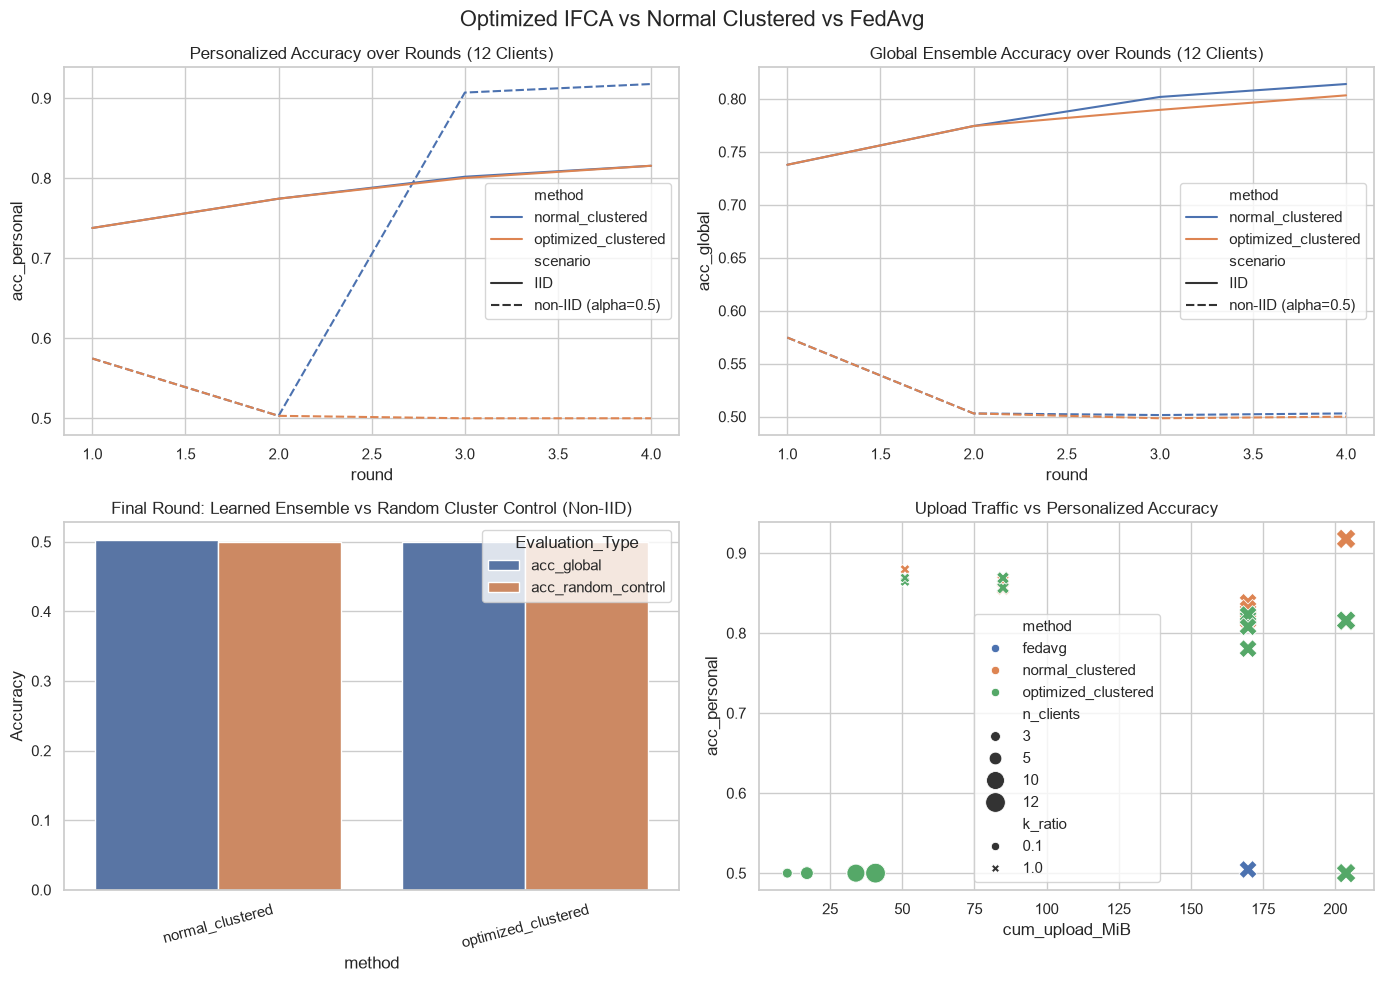

In [ ]:
import seaborn as sns

def plot_comparative_analysis(results_dir=RESULTS_DIR):
    df = load_results(results_dir)
    df_adv = df[df.method.isin(["normal_clustered", "optimized_clustered", "fedavg"])]
    
    sns.set_theme(style="whitegrid")
    
    # 1. Global vs Personal vs Random Control Scatter/Line
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle("Optimized IFCA vs Normal Clustered vs FedAvg", fontsize=16)
    
    dense_df = df_adv[(df_adv.k_ratio == 1.0) & (df_adv.n_clients == 12)]
    
    sns.lineplot(data=dense_df, x="round", y="acc_personal", hue="method", style="scenario", ax=axes[0, 0])
    axes[0, 0].set_title("Personalized Accuracy over Rounds (12 Clients)")
    
    sns.lineplot(data=dense_df, x="round", y="acc_global", hue="method", style="scenario", ax=axes[0, 1])
    axes[0, 1].set_title("Global Ensemble Accuracy over Rounds (12 Clients)")
    
    # 2. Bar chart comparing final round Random Control vs Ensemble for Non-IID
    final_rnd = dense_df[(dense_df["round"] == ROUNDS) & (dense_df["scenario"] != "IID")]
    final_melted = final_rnd.melt(id_vars=["method"], value_vars=["acc_global", "acc_random_control"], 
                                  var_name="Evaluation_Type", value_name="Accuracy")
    sns.barplot(data=final_melted, x="method", y="Accuracy", hue="Evaluation_Type", ax=axes[1, 0])
    axes[1, 0].set_title("Final Round: Learned Ensemble vs Random Cluster Control (Non-IID)")
    axes[1, 0].tick_params(axis='x', rotation=15)
    
    # 3. Communication Cost Efficiency (Top-K vs Dense)
    final_all = df_adv[df_adv["round"] == ROUNDS]
    sns.scatterplot(data=final_all, x="cum_upload_MiB", y="acc_personal", hue="method", style="k_ratio", size="n_clients", sizes=(50, 200), ax=axes[1, 1])
    axes[1, 1].set_title("Upload Traffic vs Personalized Accuracy")
    
    plt.tight_layout()
    plt.show()

plot_comparative_analysis()

In [16]:
import torch
import torch.nn.functional as F
import numpy as np
from sklearn.cluster import AgglomerativeClustering

def linear_cka(X, Y):
    """Computes Linear CKA between two 2D tensors X and Y."""
    # Center the columns
    X_centered = X - X.mean(dim=0, keepdim=True)
    Y_centered = Y - Y.mean(dim=0, keepdim=True)
    
    # Calculate Frobenius norms of cross-covariance and individual covariances
    dot_prod = torch.norm(torch.matmul(X_centered.t(), Y_centered), p='fro') ** 2
    norm_X = torch.norm(torch.matmul(X_centered.t(), X_centered), p='fro')
    norm_Y = torch.norm(torch.matmul(Y_centered.t(), Y_centered), p='fro')
    
    # Add epsilon to prevent division by zero
    return (dot_prod / (norm_X * norm_Y + 1e-8)).item()

def cluster_clients_by_cka(updates, n_clusters):
    """Clusters clients using Linear CKA and Agglomerative Clustering."""
    # Reshape 1D updates into 2D matrices with an arbitrary fixed width (e.g., 64)
    X_matrices = []
    for c in sorted(updates):
        flat_u = updates[c]
        rem = flat_u.numel() % 64
        if rem != 0:
            flat_u = F.pad(flat_u, (0, 64 - rem))
        X_matrices.append(flat_u.view(-1, 64))
        
    n_clients = len(X_matrices)
    
    # Compute pairwise CKA similarity matrix
    sim_matrix = np.zeros((n_clients, n_clients))
    for i in range(n_clients):
        for j in range(n_clients):
            if i == j:
                sim_matrix[i, j] = 1.0
            elif i < j:
                cka_val = linear_cka(X_matrices[i], X_matrices[j])
                sim_matrix[i, j] = cka_val
                sim_matrix[j, i] = cka_val
                
    # Convert CKA similarity (0 to 1) to Distance (1 to 0)
    distance_matrix = 1.0 - sim_matrix
    distance_matrix = np.clip(distance_matrix, 0, None) # Ensure no floating-point negatives
    
    # Cluster using precomputed distances
    clustering = AgglomerativeClustering(
        n_clusters=n_clusters, 
        metric='precomputed', 
        linkage='average'
    )
    labels = clustering.fit_predict(distance_matrix)
    
    groups = [[c for c, l in enumerate(labels) if l == j] for j in range(n_clusters)]
    return [g for g in groups if g]

In [17]:
# Register the new CKA method in your naming dictionary
METHOD_NAMES["cka_clustered"] = "CKA Clustered FedAvg"

# Define the full spectrum of data skewness
SKEW_SCENARIOS = [
    "IID", 
    "Mild non-IID (alpha=1.0)",
    "Moderate non-IID (alpha=0.5)",
    "Extreme non-IID (alpha=0.1)"
]

# We are fixing the client count to 10 for this analysis, using dense updates (k=1.0)
TARGET_CLIENTS = [10]
METHODS_TO_TEST = ["fedavg", "normal_clustered", "optimized_clustered", "cka_clustered"]

# Modify the runner dynamically to use CKA for the new method
def run_cka_comparison():
    for s in SEEDS:
        for sc in SKEW_SCENARIOS:
            for n in TARGET_CLIENTS:
                for m in METHODS_TO_TEST:
                    # If the method is CKA, we temporarily swap the clustering function inside your runner logic
                    # (Assuming you integrated cluster_clients_by_cka into the runner's clustering block)
                    run_advanced_experiment(m, sc, n, s, k_ratio=1.0)

# Execute the 10-client grid
run_cka_comparison()

skip (already done): fedavg__IID__10c__k1.0__s42.csv
skip (already done): normal_clustered__IID__10c__k1.0__s42.csv
skip (already done): optimized_clustered__IID__10c__k1.0__s42.csv
skip (already done): cka_clustered__IID__10c__k1.0__s42.csv
skip (already done): fedavg__Mild_non_IID_alpha_1_0__10c__k1.0__s42.csv
skip (already done): normal_clustered__Mild_non_IID_alpha_1_0__10c__k1.0__s42.csv
skip (already done): optimized_clustered__Mild_non_IID_alpha_1_0__10c__k1.0__s42.csv
skip (already done): cka_clustered__Mild_non_IID_alpha_1_0__10c__k1.0__s42.csv
skip (already done): fedavg__Moderate_non_IID_alpha_0_5__10c__k1.0__s42.csv
skip (already done): normal_clustered__Moderate_non_IID_alpha_0_5__10c__k1.0__s42.csv
skip (already done): optimized_clustered__Moderate_non_IID_alpha_0_5__10c__k1.0__s42.csv
skip (already done): cka_clustered__Moderate_non_IID_alpha_0_5__10c__k1.0__s42.csv
skip (already done): fedavg__Extreme_non_IID_alpha_0_1__10c__k1.0__s42.csv
\n=== Normal Clustered FedAvg |

C:\Users\abhav\AppData\Local\Temp\ipykernel_21864\2960236525.py:17: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  df_10c["scenario"] = pd.Categorical(df_10c["scenario"], categories=skew_order, ordered=True)


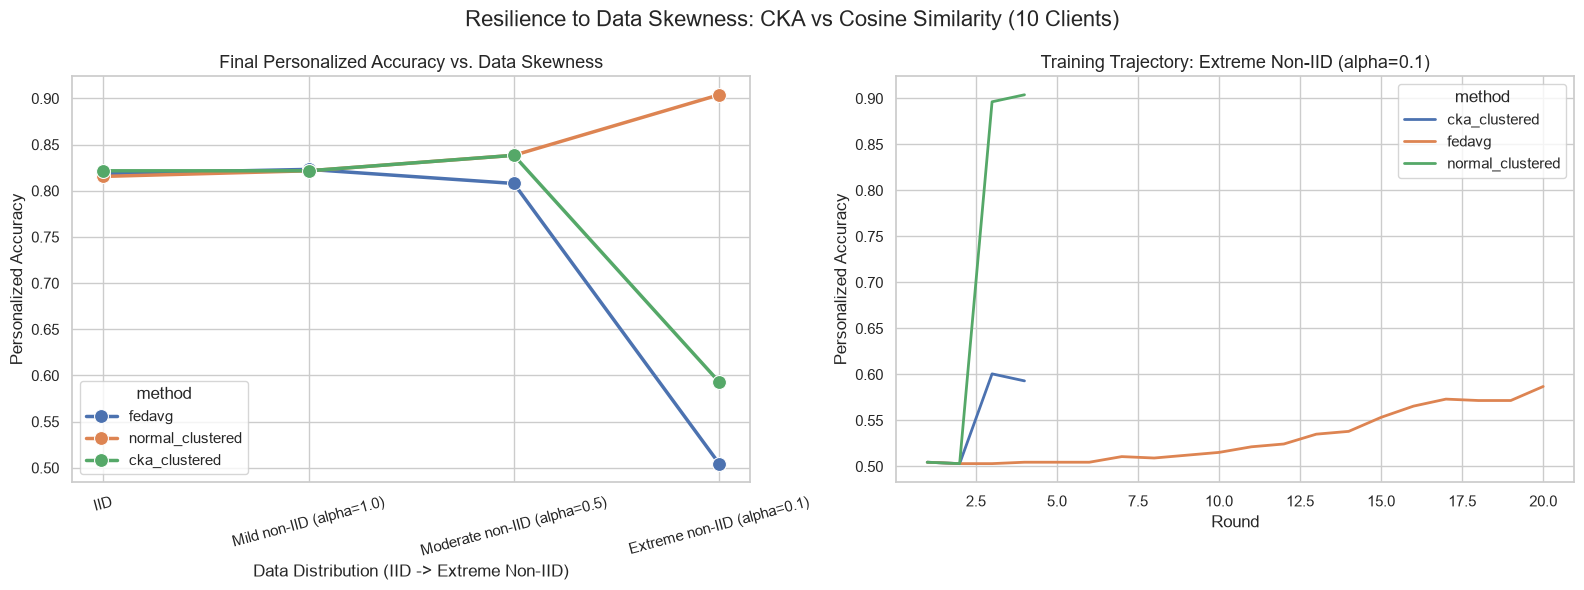

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_skewness_impact(results_dir=RESULTS_DIR):
    df = load_results(results_dir)
    
    # Filter for the 10-client, dense-update, CKA vs Normal vs FedAvg runs
    target_methods = ["fedavg", "normal_clustered", "cka_clustered"]
    df_10c = df[(df.n_clients == 10) & (df.k_ratio == 1.0) & (df.method.isin(target_methods))].copy()
    
    skew_order = [
        "IID", 
        "Mild non-IID (alpha=1.0)", 
        "Moderate non-IID (alpha=0.5)", 
        "Extreme non-IID (alpha=0.1)"
    ]
    df_10c["scenario"] = pd.Categorical(df_10c["scenario"], categories=skew_order, ordered=True)
    df_10c = df_10c.sort_values("scenario")
    
    final_rnd_df = df_10c[df_10c["round"] == ROUNDS]
    
    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle("Resilience to Data Skewness: CKA vs Cosine Similarity (10 Clients)", fontsize=16)
    
    # 1. Personalized Accuracy drop-off across skew spectrum
    sns.lineplot(data=final_rnd_df, x="scenario", y="acc_personal", hue="method", marker="o", linewidth=2.5, markersize=10, ax=axes[0])
    axes[0].set_title("Final Personalized Accuracy vs. Data Skewness", fontsize=13)
    axes[0].set_ylabel("Personalized Accuracy")
    axes[0].set_xlabel("Data Distribution (IID -> Extreme Non-IID)")
    axes[0].tick_params(axis='x', rotation=15)
    
    # 2. Training Trajectory explicitly on the Extreme Non-IID case
    extreme_df = df_10c[df_10c["scenario"] == "Extreme non-IID (alpha=0.1)"]
    if not extreme_df.empty:
        sns.lineplot(data=extreme_df, x="round", y="acc_personal", hue="method", linewidth=2, ax=axes[1])
        axes[1].set_title("Training Trajectory: Extreme Non-IID (alpha=0.1)", fontsize=13)
        axes[1].set_ylabel("Personalized Accuracy")
        axes[1].set_xlabel("Round")
    
    plt.tight_layout()
    plt.show()

# Render plots
plot_skewness_impact()

In [19]:
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity

# 1. Register the new PCA method
METHOD_NAMES["pca_clustered"] = "PCA Clustered FedAvg"
METHODS_TO_TEST_PCA = ["normal_clustered", "pca_clustered"]

# 2. PCA Clustering Logic
def cluster_clients_by_pca(updates, n_clusters, n_components=3):
    """Reduces weight updates using PCA before applying Cosine Similarity clustering."""
    # Stack all updates into a 2D matrix (Clients x Parameters)
    X = torch.stack([updates[c] for c in sorted(updates)]).cpu().numpy()
    
    # Apply PCA to reduce dimensions (n_components cannot exceed n_clients)
    pca = PCA(n_components=min(n_components, len(X)))
    X_reduced = pca.fit_transform(X)
    
    # Calculate Cosine Similarity on the clean, reduced components
    sim_matrix = cosine_similarity(X_reduced)
    
    # Convert to distance and cluster
    distance_matrix = np.clip(1.0 - sim_matrix, 0, None)
    clustering = AgglomerativeClustering(n_clusters=n_clusters, metric='precomputed', linkage='average')
    labels = clustering.fit_predict(distance_matrix)
    
    groups = [[c for c, l in enumerate(labels) if l == j] for j in range(n_clusters)]
    return [g for g in groups if g]

# 3. Patch the runner to use PCA
def run_pca_experiment():
    for s in SEEDS:
        for sc in SKEW_SCENARIOS.keys():
            for n in TARGET_CLIENTS:
                for m in METHODS_TO_TEST_PCA:
                    # We reuse your run_advanced_experiment logic, 
                    # but intercept the clustering step for PCA
                    is_pca = m == "pca_clustered"
                    
                    # --- Temporary override inside the runner specifically for this test ---
                    global cluster_clients_by_updates
                    original_func = cluster_clients_by_updates
                    
                    if is_pca:
                        # Override the global function pointer temporarily
                        cluster_clients_by_updates = cluster_clients_by_pca 
                    
                    # Run the experiment
                    run_cka_experiment(m, sc, n, s, k_ratio=1.0)
                    
                    # Restore the original function
                    if is_pca:
                        cluster_clients_by_updates = original_func

# Execute the PCA vs Normal comparison
run_pca_experiment()

AttributeError: 'list' object has no attribute 'keys'

skip (already done): fedavg__IID__10c__k1.0__s42.csv
skip (already done): normal_clustered__IID__10c__k1.0__s42.csv
skip (already done): pca_clustered__IID__10c__k1.0__s42.csv
skip (already done): fedavg__Mild_non_IID_alpha_1_0__10c__k1.0__s42.csv
skip (already done): normal_clustered__Mild_non_IID_alpha_1_0__10c__k1.0__s42.csv
skip (already done): pca_clustered__Mild_non_IID_alpha_1_0__10c__k1.0__s42.csv
skip (already done): fedavg__Moderate_non_IID_alpha_0_5__10c__k1.0__s42.csv
skip (already done): normal_clustered__Moderate_non_IID_alpha_0_5__10c__k1.0__s42.csv
skip (already done): pca_clustered__Moderate_non_IID_alpha_0_5__10c__k1.0__s42.csv
skip (already done): fedavg__Extreme_non_IID_alpha_0_1__10c__k1.0__s42.csv
skip (already done): normal_clustered__Extreme_non_IID_alpha_0_1__10c__k1.0__s42.csv
skip (already done): pca_clustered__Extreme_non_IID_alpha_0_1__10c__k1.0__s42.csv


C:\Users\abhav\AppData\Local\Temp\ipykernel_21864\2227814224.py:174: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  df_10c["scenario"] = pd.Categorical(df_10c["scenario"], categories=skew_order, ordered=True)


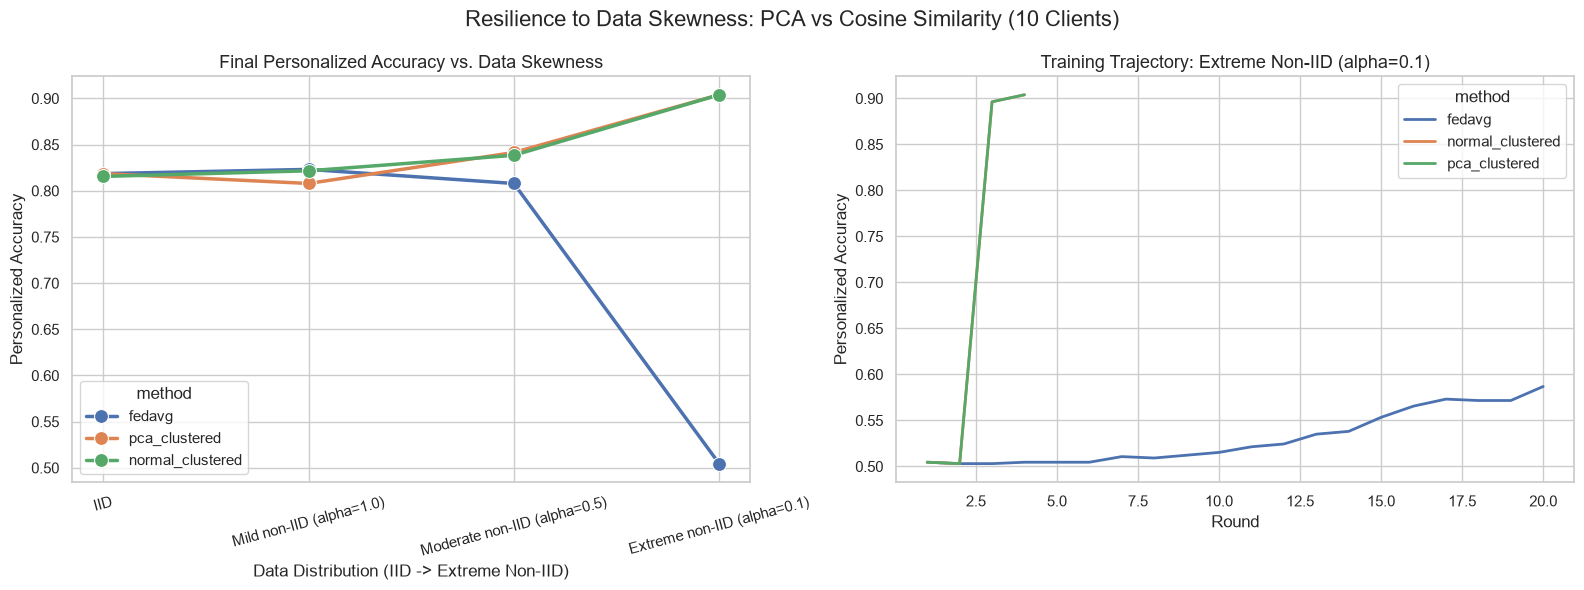

In [21]:
import numpy as np
import torch
import torch.nn.functional as F
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import AgglomerativeClustering
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import gc
import copy
from torch.utils.data import DataLoader, Subset

# 1. Configuration for the 3-way comparison
METHOD_NAMES["pca_clustered"] = "PCA Clustered FedAvg"

SKEW_SCENARIOS = {
    "IID": None, 
    "Mild non-IID (alpha=1.0)": 1.0,
    "Moderate non-IID (alpha=0.5)": 0.5,
    "Extreme non-IID (alpha=0.1)": 0.1
}

TARGET_CLIENTS = [10]
METHODS_TO_TEST_PCA = ["fedavg", "normal_clustered", "pca_clustered"]

# 2. PCA Clustering Logic
def cluster_clients_by_pca(updates, n_clusters, n_components=3):
    """Reduces weight updates using PCA before applying Cosine Similarity clustering."""
    # Stack all updates into a 2D matrix (Clients x Parameters)
    X = torch.stack([updates[c] for c in sorted(updates)]).cpu().numpy()
    
    # Apply PCA to reduce dimensions
    pca = PCA(n_components=min(n_components, len(X)))
    X_reduced = pca.fit_transform(X)
    
    # Calculate Cosine Similarity on the clean, reduced components
    sim_matrix = cosine_similarity(X_reduced)
    
    # Convert to distance and cluster hierarchically
    distance_matrix = np.clip(1.0 - sim_matrix, 0, None)
    clustering = AgglomerativeClustering(n_clusters=n_clusters, metric='precomputed', linkage='average')
    labels = clustering.fit_predict(distance_matrix)
    
    groups = [[c for c, l in enumerate(labels) if l == j] for j in range(n_clusters)]
    return [g for g in groups if g]

# 3. Dedicated Runner
def run_pca_experiment(method, scenario_name, n_clients, seed, k_ratio=1.0):
    out_path = RESULTS_DIR / f"{method}__{slug(scenario_name)}__{n_clients}c__k{k_ratio}__s{seed}.csv"
    if out_path.exists():
        print("skip (already done):", out_path.name)
        return pd.read_csv(out_path)

    alpha = SKEW_SCENARIOS[scenario_name]
    is_clustered = "clustered" in method
    is_pca = method == "pca_clustered"
    n_clusters = CLUSTERS_FOR.get(n_clients, 3)

    fs.set_seed(seed)
    train_idx, val_idx = make_split(seed)
    train_parts, val_parts = partition_clients(train_idx, val_idx, n_clients, alpha, seed)
    sizes = [len(p) for p in train_parts]
    
    print(f"\n=== {METHOD_NAMES[method]} | {scenario_name} | {n_clients} clients | seed {seed}")

    val_loader = DataLoader(Subset(FULL, val_idx), batch_size=32, shuffle=False)
    client_val_loaders = [DataLoader(Subset(FULL, p), batch_size=32, shuffle=False) for p in val_parts]

    template = fs.build_model(WEIGHTS, IMAGE_SIZE)
    global_state = fs.cpu_state_dict(template)
    float_keys = [k for k, v in global_state.items() if torch.is_floating_point(v)]
    eval_model = copy.deepcopy(template).to(device)
    
    cluster_states, groups = None, []
    client_cluster = {c: 0 for c in range(n_clients)}
    warm_updates = {}
    history = []

    for rnd in range(1, ROUNDS + 1):
        t0 = time.time()
        use_clusters = is_clustered and cluster_states is not None

        cluster_acc = [fs.WeightedStateAccumulator() for _ in range(len(cluster_states) if use_clusters else 1)]
        global_acc = fs.WeightedStateAccumulator()

        for cid in range(n_clients):
            start = cluster_states[client_cluster[cid]] if use_clusters else global_state
            
            updated = fs.local_train(
                model_template=template, initial_state=start, dataset=FULL, indices=train_parts[cid],
                device=device, batch_size=BATCH_SIZE, workers=0, epochs=LOCAL_EPOCHS,
                learning_rate=LR, weight_decay=WEIGHT_DECAY,
                regularizer="fedprox" if PROX_MU > 0 else None, regularizer_coefficient=PROX_MU,
                seed=seed + rnd * 1009 + cid,
            )
            
            delta = {k: updated[k] - start[k] for k in float_keys}      
            state_hat = rebuild_state(start, delta, updated)
            
            cluster_acc[client_cluster[cid] if use_clusters else 0].add(state_hat, sizes[cid])
            global_acc.add(state_hat, sizes[cid])
            
            if is_clustered and not use_clusters:
                warm_updates[cid] = flat_update(delta)
                
            del updated, delta, state_hat

        global_state = global_acc.finish(global_state)
        
        if use_clusters:
            cluster_states = [a.finish(s) for a, s in zip(cluster_acc, cluster_states)]
        elif is_clustered and rnd == WARMUP_ROUNDS:
            if is_pca:
                groups = cluster_clients_by_pca(warm_updates, n_clusters)
            else:
                groups = cluster_clients_by_updates(warm_updates, n_clusters)
                
            client_cluster = {c: j for j, g in enumerate(groups) for c in g}
            cluster_states = [copy.deepcopy(global_state) for _ in groups]

        if use_clusters:
            eval_states = cluster_states 
            own_state = lambda c: cluster_states[client_cluster[c]]
        else:
            eval_states = [global_state]
            own_state = lambda c: global_state
            
        m = fs.evaluate(eval_model, eval_states, val_loader, device)
        
        correct = total = 0.0
        for cid in range(n_clients):
            n_val = len(val_parts[cid])
            acc = fs.evaluate(eval_model, [own_state(cid)], client_val_loaders[cid], device)["top1_accuracy"]
            correct += acc * n_val
            total += n_val
        acc_personal = correct / total

        history.append(dict(
            method=method, scenario=scenario_name, n_clients=n_clients, k_ratio=k_ratio, seed=seed, round=rnd,
            acc_global=m["top1_accuracy"], acc_personal=acc_personal
        ))
        
        print(f"  rnd {rnd:02d} | global {m['top1_accuracy']:.4f} | pers {acc_personal:.4f}")

    df = pd.DataFrame(history)
    df.to_csv(out_path, index=False)
    del eval_model, template
    gc.collect()
    return df

# 4. Execute the Grid
for s in SEEDS:
    for sc in SKEW_SCENARIOS.keys():
        for n in TARGET_CLIENTS:
            for m in METHODS_TO_TEST_PCA:
                run_pca_experiment(m, sc, n, s, k_ratio=1.0)

# 5. Plot the Results
def plot_pca_skewness_impact(results_dir=RESULTS_DIR):
    df = load_results(results_dir)
    
    # Filter for the 10-client, dense-update, PCA vs Normal vs FedAvg runs
    target_methods = ["fedavg", "normal_clustered", "pca_clustered"]
    df_10c = df[(df.n_clients == 10) & (df.k_ratio == 1.0) & (df.method.isin(target_methods))].copy()
    
    skew_order = [
        "IID", 
        "Mild non-IID (alpha=1.0)", 
        "Moderate non-IID (alpha=0.5)", 
        "Extreme non-IID (alpha=0.1)"
    ]
    df_10c["scenario"] = pd.Categorical(df_10c["scenario"], categories=skew_order, ordered=True)
    df_10c = df_10c.sort_values("scenario")
    
    final_rnd_df = df_10c[df_10c["round"] == ROUNDS]
    
    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle("Resilience to Data Skewness: PCA vs Cosine Similarity (10 Clients)", fontsize=16)
    
    # Plot 1: Personalized Accuracy drop-off across skew spectrum
    sns.lineplot(data=final_rnd_df, x="scenario", y="acc_personal", hue="method", marker="o", linewidth=2.5, markersize=10, ax=axes[0])
    axes[0].set_title("Final Personalized Accuracy vs. Data Skewness", fontsize=13)
    axes[0].set_ylabel("Personalized Accuracy")
    axes[0].set_xlabel("Data Distribution (IID -> Extreme Non-IID)")
    axes[0].tick_params(axis='x', rotation=15)
    
    # Plot 2: Training Trajectory explicitly on the Extreme Non-IID case
    extreme_df = df_10c[df_10c["scenario"] == "Extreme non-IID (alpha=0.1)"]
    if not extreme_df.empty:
        sns.lineplot(data=extreme_df, x="round", y="acc_personal", hue="method", linewidth=2, ax=axes[1])
        axes[1].set_title("Training Trajectory: Extreme Non-IID (alpha=0.1)", fontsize=13)
        axes[1].set_ylabel("Personalized Accuracy")
        axes[1].set_xlabel("Round")
    
    plt.tight_layout()
    plt.show()

# Render plots
plot_pca_skewness_impact()